# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Du, Rukaya Selim, Adeline Kwakye

**Date:** 11/9/2026

Df shape: 



(16814, 19)

column information: 

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 

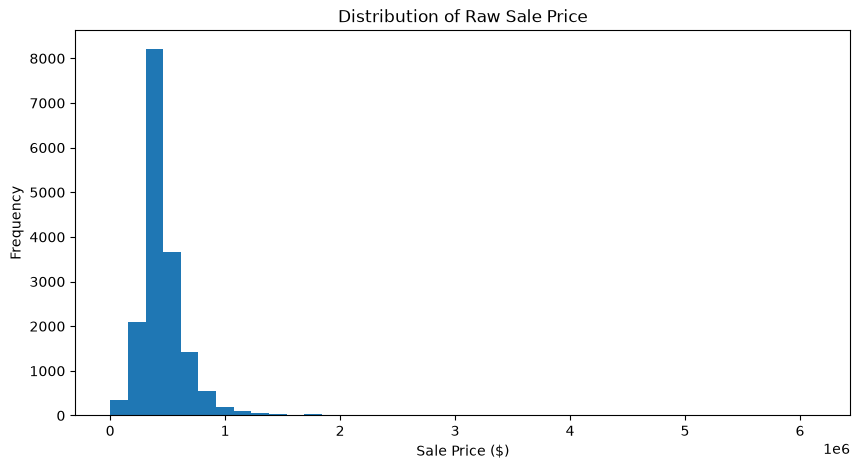

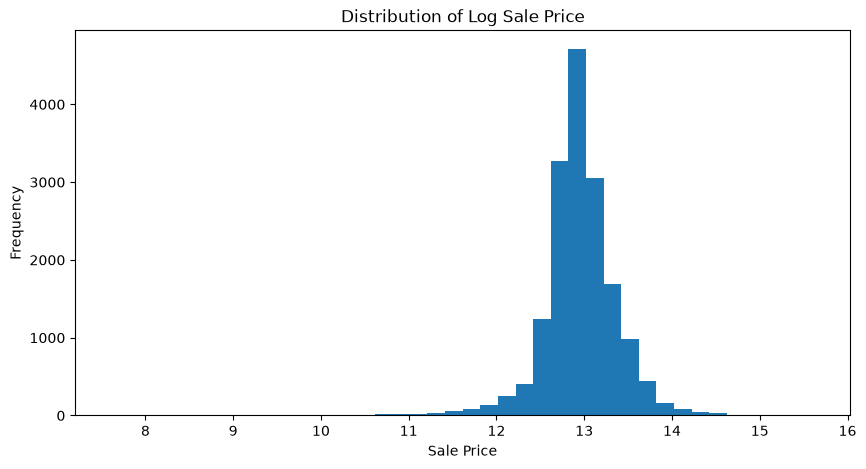

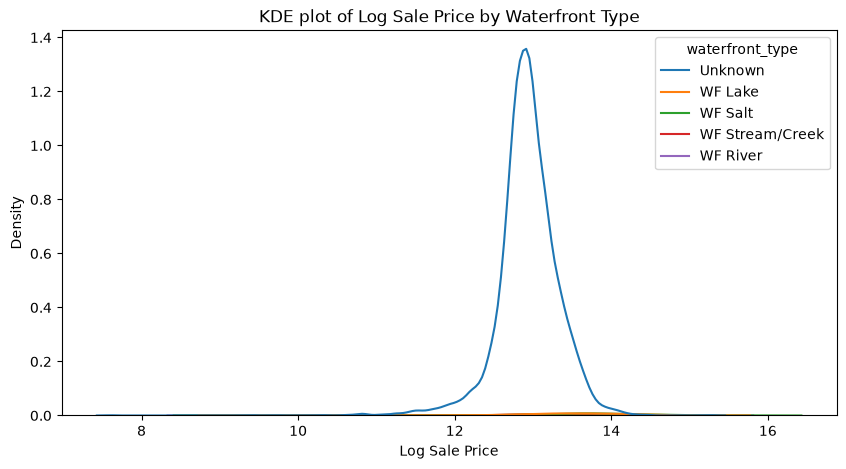

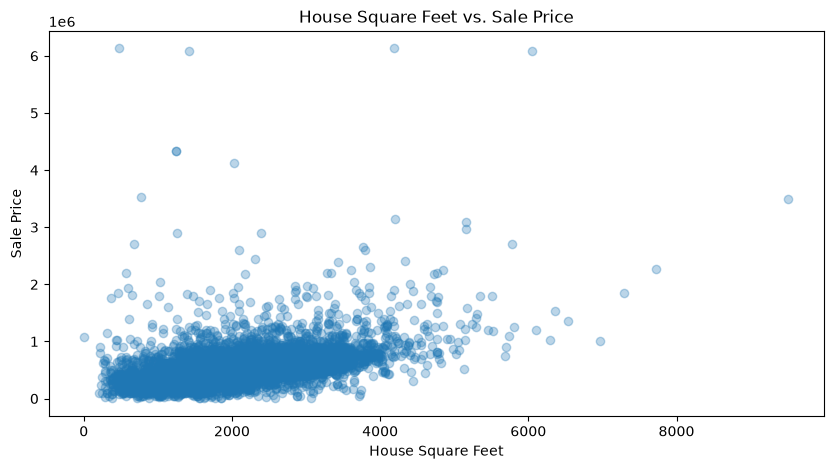

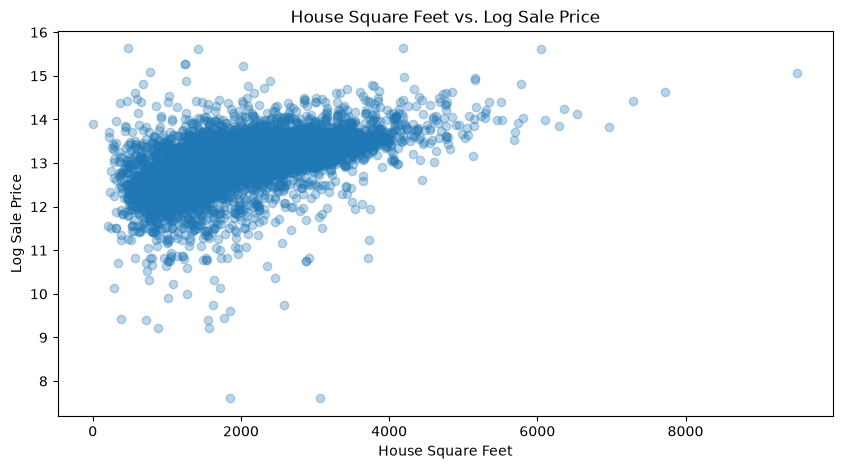

In [1]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Question 1
df = pd.read_csv("data/pierce_county_house_sales.csv")

#shape
print("Df shape: \n")
display(df.shape)
print("column information: \n")
df.info()
print("duplicated rows count: \n", df.duplicated().sum()) # 46
print("missing values count: \n", df.isna().sum())
print("numerical summary: \n", df.describe())

# drop duplicated
house_df = df.copy()
house_df = house_df.drop_duplicates()
print(house_df.duplicated().sum) # verify that sum is 0

# inspect missing values 
print(house_df['waterfront_type'].value_counts(dropna=False))
print(house_df['view_quality'].value_counts(dropna=False))


print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price'
).head(10))

print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price', ascending=False
).head(10))



# handle missing data 
house_df['waterfront_type'] = house_df['waterfront_type'].fillna('Unknown')

house_df['view_quality'] = house_df['view_quality'].fillna('Unknown')

print(house_df[['waterfront_type', 'view_quality']].isnull().sum())  # verify missing data is 0 


categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality'
]

house_df[categorical_columns] = house_df[categorical_columns].fillna('Unknown')

# convert sale_date to be a datetime
house_df['sale_date'] = pd.to_datetime(house_df['sale_date'])
print(house_df['sale_date'].dtype)

# eda visualization
    # histogram for sale price raw data

plt.figure(figsize=(10, 5))
house_df['sale_price'].hist(bins=40, grid=False)
plt.title("Distribution of Raw Sale Price")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.show()

# histogram of log-transformed sale price
plt.figure(figsize=(10,5))
house_df['sale_price_log'] = np.log(house_df['sale_price'])
house_df['sale_price_log'].hist(bins=40, grid=False)
plt.title("Distribution of Log Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# kde plot
plt.figure(figsize=(10, 5))

sns.kdeplot(data=house_df, x='sale_price_log', hue='waterfront_type')
plt.title("KDE plot of Log Sale Price by Waterfront Type")
plt.xlabel("Log Sale Price")
plt.ylabel("Density")
plt.show()

# scatter plot raw version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price'], alpha=0.3)
plt.title("House Square Feet vs. Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

# scatterplot log version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price_log'], alpha=0.3)
plt.title("House Square Feet vs. Log Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Log Sale Price")
plt.show()


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)


# Question 2: transform categorical variables
house_df.dtypes

categorical_columns = house_df.select_dtypes(include=['object', 'str']).columns
print(categorical_columns) 

# Identify categorical columns
categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality',
    'utility_sewer'
]

# One-hot encode categorical variables
house_encoded = pd.get_dummies(
    house_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Inspect transformed dataset
print("Dataset shape:", house_encoded.shape)
print(house_encoded.dtypes)


Index(['hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='str')
Dataset shape: (16768, 62)
sale_date                                  datetime64[us]
sale_price                                          int64
house_square_feet                                   int64
attic_finished_square_feet                          int64
basement_square_feet                                int64
attached_garage_square_feet                         int64
detached_garage_square_feet                         int64
fireplaces                                          int64
stories                                             int64
year_built                                          int64
bedrooms                                            int64
bathrooms                                           int64
sale_price_log                                    float64
hvac_description_Electric Baseboard                 int64
hvac_description_

In [3]:
# Question 3 : implement 80/20 train-test split
from sklearn.model_selection import train_test_split
# target variable
y = house_encoded["sale_price"]
# features
X = house_encoded.drop(
    columns=['sale_price','sale_date', 'sale_price_log']
)

# split 80/20
(X_train, X_test, y_train, y_test) = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42
)
print("Training shape:\n")
print("X_train: \n", X_train.shape)
print("y_train: \n", y_train.shape)
print("X_test: \n", X_test.shape)
print("y_test: \n", y_test.shape)

print("\nTraining target summary:\n", y_train.describe())

Training shape:

X_train: 
 (13414, 59)
y_train: 
 (13414,)
X_test: 
 (3354, 59)
y_test: 
 (3354,)

Training target summary:
 count    1.341400e+04
mean     4.619475e+05
std      2.395054e+05
min      2.000000e+03
25%      3.475500e+05
50%      4.170000e+05
75%      5.240000e+05
max      6.130000e+06
Name: sale_price, dtype: float64


### Questions 4-6: Regression analysis

**AI use:** ChatGPT (GPT-6) was used to help develop Questions 4-6. Questions 1-3 above are the original work on Adeline's branch and were not rewritten here. All three questions below reuse `X_train`, `X_test`, `y_train`, and `y_test` from Question 3. The original Phase 2 starter remains untouched.

#### Question 4: Baseline regression models
Fit three ordinary least-squares models without nonlinear terms or interactions. One-hot indicators created in Question 2 are retained in the full-feature baseline. Evaluate RMSE and R-squared on both training and test sets.

In [4]:
# Question 4: Baseline regression models
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

numeric_predictors = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet",
    "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"
]
assert all(k in X_train.columns for k in numeric_predictors)
assert X_train.select_dtypes(exclude=["number", "bool"]).empty, "Q3 predictors must be numeric"
assert X_train.notna().all().all() and X_test.notna().all().all(), "Missing predictors"

baseline_sets = {
    "A: square footage": ["house_square_feet"],
    "B: size + beds + baths + year": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "C: all encoded predictors": X_train.columns.to_list(),
}

def regression_metrics(model, x, y):
    pred = model.predict(x)
    return float(np.sqrt(mean_squared_error(y, pred))), float(r2_score(y, pred))

baseline_models = {}
baseline_scores = []
for model_name, features in baseline_sets.items():
    estimator = LinearRegression()
    estimator.fit(X_train[features], y_train)
    tr_rmse, tr_r2 = regression_metrics(estimator, X_train[features], y_train)
    te_rmse, te_r2 = regression_metrics(estimator, X_test[features], y_test)
    baseline_models[model_name] = estimator
    baseline_scores.append({
        "Model": model_name, "Features": len(features),
        "Train RMSE ($)": tr_rmse, "Train R2": tr_r2,
        "Test RMSE ($)": te_rmse, "Test R2": te_r2
    })
baseline_table = pd.DataFrame(baseline_scores).set_index("Model")
display(baseline_table.round(3))
q4_best = baseline_table["Test RMSE ($)"].idxmin()
print("Q4 lowest test RMSE:", q4_best)
print("Note: for formal model selection, prefer CV within the training data; "
      "test results are displayed because the assignment explicitly requests them.")

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
A: square footage,1,203540.166,0.278,189646.864,0.270
B: size + beds + baths + year,4,199738.891,0.304,185108.036,0.305
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517


Q4 lowest test RMSE: C: all encoded predictors
Note: for formal model selection, prefer CV within the training data; test results are displayed because the assignment explicitly requests them.


#### Question 5: Partial regression plots
For each original numeric predictor in the full encoded model, regress both that predictor and sale price on the remaining predictors, then plot their residuals. This isolates the partial linear association while holding the other predictors fixed. The orange binned trend helps identify departures from a straight line. Inspect the plots for curvature or jumps; these are exploratory patterns, not formal significance tests.

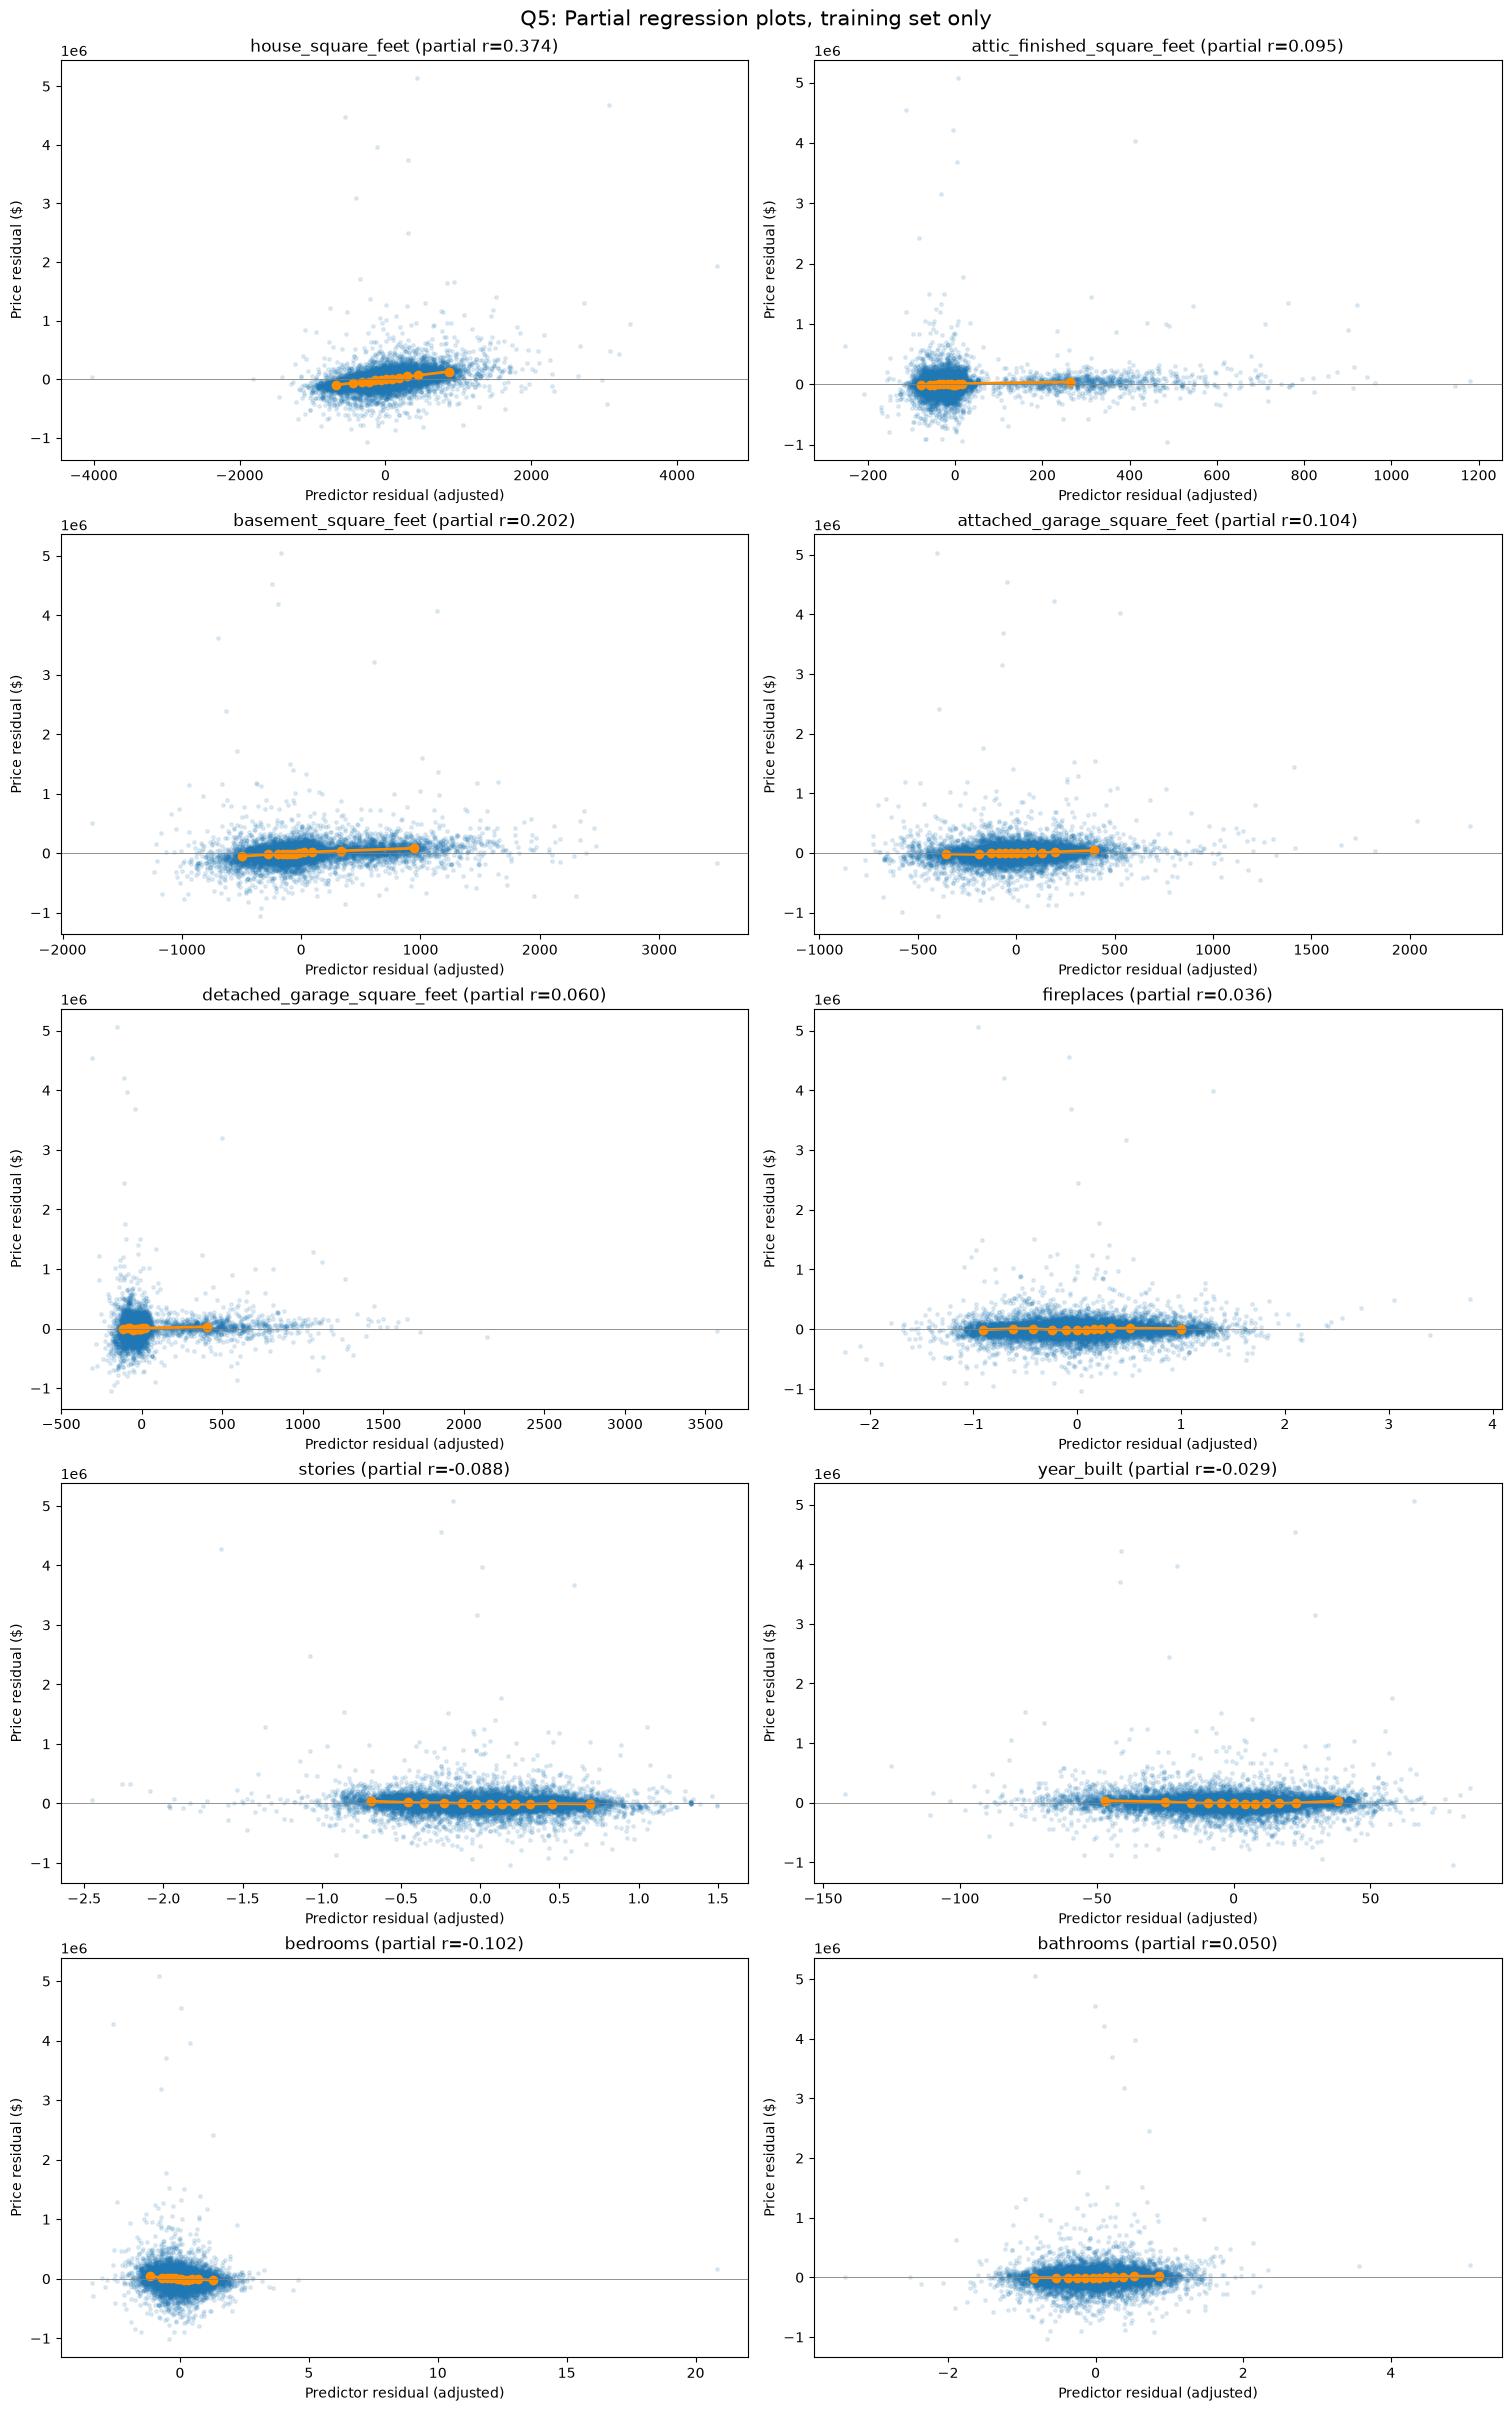

,Predictor,Partial correlation
0,house_square_feet,0.374
1,attic_finished_square_feet,0.095
2,basement_square_feet,0.202
3,attached_garage_square_feet,0.104
4,detached_garage_square_feet,0.060
5,fireplaces,0.036
6,stories,-0.088
7,year_built,-0.029
8,bedrooms,-0.102
9,bathrooms,0.050


In [5]:
# Question 5: Partial regression plots
from pathlib import Path

full_features = baseline_sets["C: all encoded predictors"]
fig, axes = plt.subplots(5, 2, figsize=(15, 24), constrained_layout=True)
partial_results = []
for ax, feature in zip(axes.flat, numeric_predictors):
    other_features = [c for c in full_features if c != feature]
    residual_y = y_train.to_numpy() - LinearRegression().fit(
        X_train[other_features], y_train
    ).predict(X_train[other_features])
    residual_x = X_train[feature].to_numpy() - LinearRegression().fit(
        X_train[other_features], X_train[feature]
    ).predict(X_train[other_features])
    cor = float(np.corrcoef(residual_x, residual_y)[0, 1])
    ax.scatter(residual_x, residual_y, s=6, alpha=0.13)
    # A binned trend can reveal curvature without fitting a nonlinear model.
    trends = pd.DataFrame({"x": residual_x, "y": residual_y})
    trends["bin"] = pd.qcut(trends["x"], q=12, duplicates="drop")
    trend = trends.groupby("bin", observed=True)[["x", "y"]].mean().sort_values("x")
    ax.plot(trend["x"], trend["y"], color="darkorange", marker="o", linewidth=2)
    ax.axhline(0, color="gray", linewidth=.6)
    ax.set(title=f"{feature} (partial r={cor:.3f})",
           xlabel="Predictor residual (adjusted)", ylabel="Price residual ($)")
    partial_results.append({"Predictor": feature, "Partial correlation": cor})
fig.suptitle("Q5: Partial regression plots, training set only", fontsize=15)
fig.savefig("Q5_partial_regression_plots.png", dpi=150)
plt.show()
display(pd.DataFrame(partial_results).round(3))

#### Question 6: More complex model
Retain the Q4 full model, then add interpretable nonlinear and interaction terms. The square-footage-squared and age-squared terms allow curvature; size × bathrooms and size × garage allow conditional relationships. Log transformations of basement and garage area allow diminishing effects. Only original input variables and a fixed reference year are used.

In [6]:
# Question 6: Complex regression
def add_complex_terms(frame):
    out = frame.copy()
    s = frame["house_square_feet"]
    age = 2020 - frame["year_built"]
    out["square_feet_squared"] = (s / 1000) ** 2
    out["age_squared"] = (age / 10) ** 2
    out["size_x_bathrooms"] = (s / 1000) * frame["bathrooms"]
    out["size_x_attached_garage"] = (s / 1000) * frame["attached_garage_square_feet"] / 1000
    out["log1p_basement_area"] = np.log1p(frame["basement_square_feet"])
    out["log1p_garage_area"] = np.log1p(frame["attached_garage_square_feet"])
    return out

X_train_complex = add_complex_terms(X_train)
X_test_complex = add_complex_terms(X_test)
assert list(X_train_complex.columns) == list(X_test_complex.columns)
complex_model = LinearRegression().fit(X_train_complex, y_train)
tr_rmse, tr_r2 = regression_metrics(complex_model, X_train_complex, y_train)
te_rmse, te_r2 = regression_metrics(complex_model, X_test_complex, y_test)
comparison = baseline_table.loc[["C: all encoded predictors"]].copy()
comparison.loc["D: transformed + interactions"] = [
    X_train_complex.shape[1], tr_rmse, tr_r2, te_rmse, te_r2
]
display(comparison.round(3))
print(f"Change in test RMSE, complex minus baseline: "
      f"${te_rmse - baseline_table.loc['C: all encoded predictors', 'Test RMSE ($)']:,.0f}")
print(f"Change in test R2, complex minus baseline: "
      f"{te_r2 - baseline_table.loc['C: all encoded predictors', 'Test R2']:+.3f}")
print("Compare both train and test results: better training fit alone does not "
      "prove better generalization. Large outliers can strongly influence RMSE.")

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517
D: transformed + interactions,65,157687.339,0.566,153580.623,0.521


Change in test RMSE, complex minus baseline: $-797
Change in test R2, complex minus baseline: +0.005
Compare both train and test results: better training fit alone does not prove better generalization. Large outliers can strongly influence RMSE.


**Q4-Q6 interpretation guidance:** Lower test RMSE and higher test R-squared indicate better test performance. Check how large the train/test gap is before claiming the complex model generalizes better. The Q5 plots may support curved terms (e.g., age or area), but they cannot by themselves establish statistical significance. The exact numbers in the tables are calculated by the code above, using Adeline's preprocessing and split.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]